### Lab 4: Regression Analysis with Regularization Techniques

**Name:** Aditya Rayarapu  
**Course:** MSCS-634 — Advanced Big Data and Data Mining  

### Learning objectives

1. Inspect and prepare a real-world regression dataset.
2. Train **simple linear**, **multiple linear**, and **polynomial** regression models.
3. Apply **Ridge (L2)** and **Lasso (L1)** regularization to polynomial features.
4. Evaluate each model using **MAE, MSE, RMSE, and R²** on a common held-out test set.
5. Analyze overfitting, hyperparameter sensitivity, coefficient shrinkage, and overall model performance.

**Reproducibility:** The dataset loads directly from `sklearn.datasets` (no external CSV or network connection required). A fixed `random_state=42` provides a consistent train/test split. Hyperparameter tuning uses *training data only*.

### 1. Setup and data preparation

The Diabetes dataset has 442 records, 10 numeric baseline features, and a continuous target reflecting disease progression one year after baseline. We examine its shape, summary statistics, missing values, duplicated rows, and feature/target distributions before fitting the models.

In [8]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
IMG_DIR = Path('screenshots')
IMG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
pd.set_option('display.max_columns', 25)
print('Libraries imported successfully. Figures will be saved in:', IMG_DIR.resolve())

Libraries imported successfully. Figures will be saved in: /Users/adityarayarapu/Downloads/MSCS-634-Lab-4/screenshots


In [9]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()
print('Dataset dimensions (rows, columns):', df.shape)
print('Feature names:', diabetes.feature_names)
print('Target name:', diabetes.target.name)
display(df.head())
display(df.describe().T.round(3))
print('\nData types:')
print(df.dtypes)

missing = df.isna().sum().rename('missing_count')
print('\nMissing values by column:')
display(missing.to_frame())
print('Total missing entries:', int(missing.sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Target minimum / maximum:', df['target'].min(), '/', df['target'].max())

Dataset dimensions (rows, columns): (442, 11)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target name: target


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136



Data types:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

Missing values by column:


,missing_count
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Total missing entries: 0
Duplicate rows: 0
Target minimum / maximum: 25.0 / 346.0


No duplicate records were found.


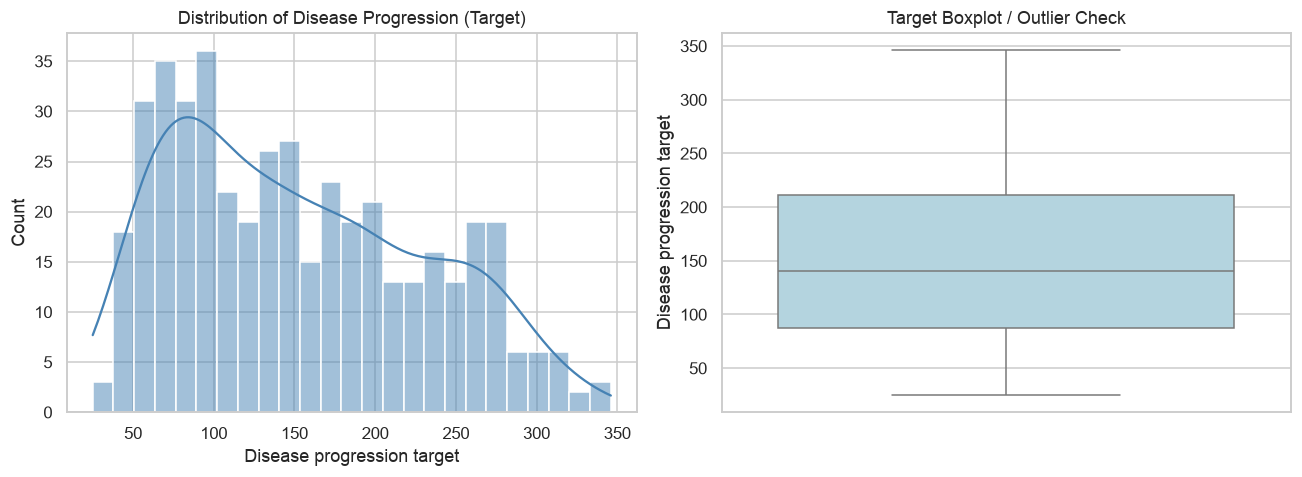

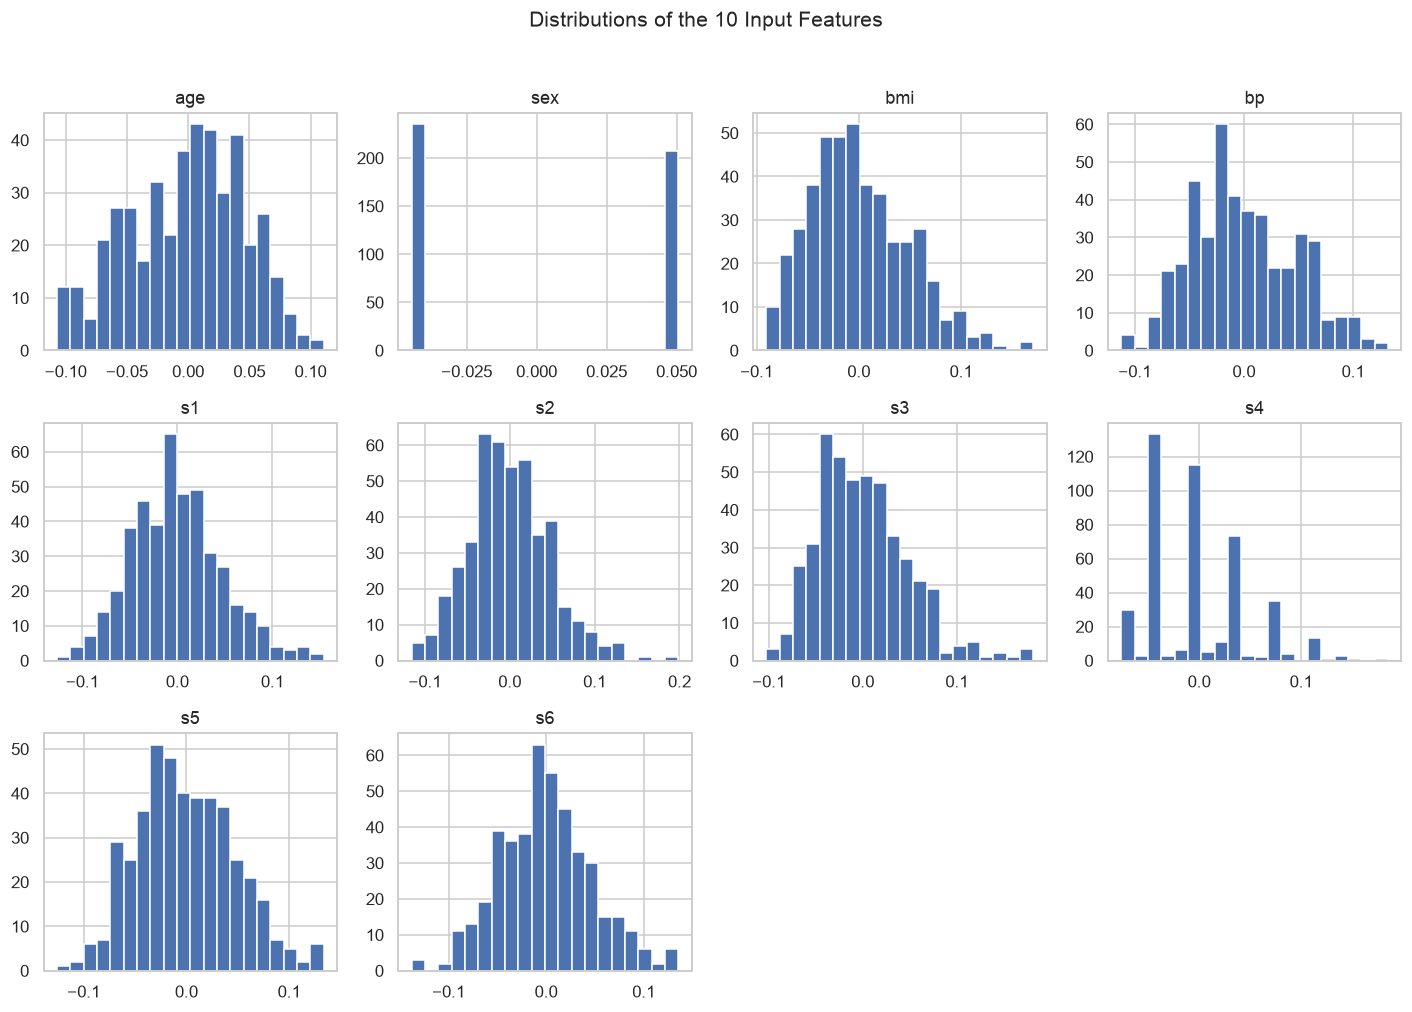

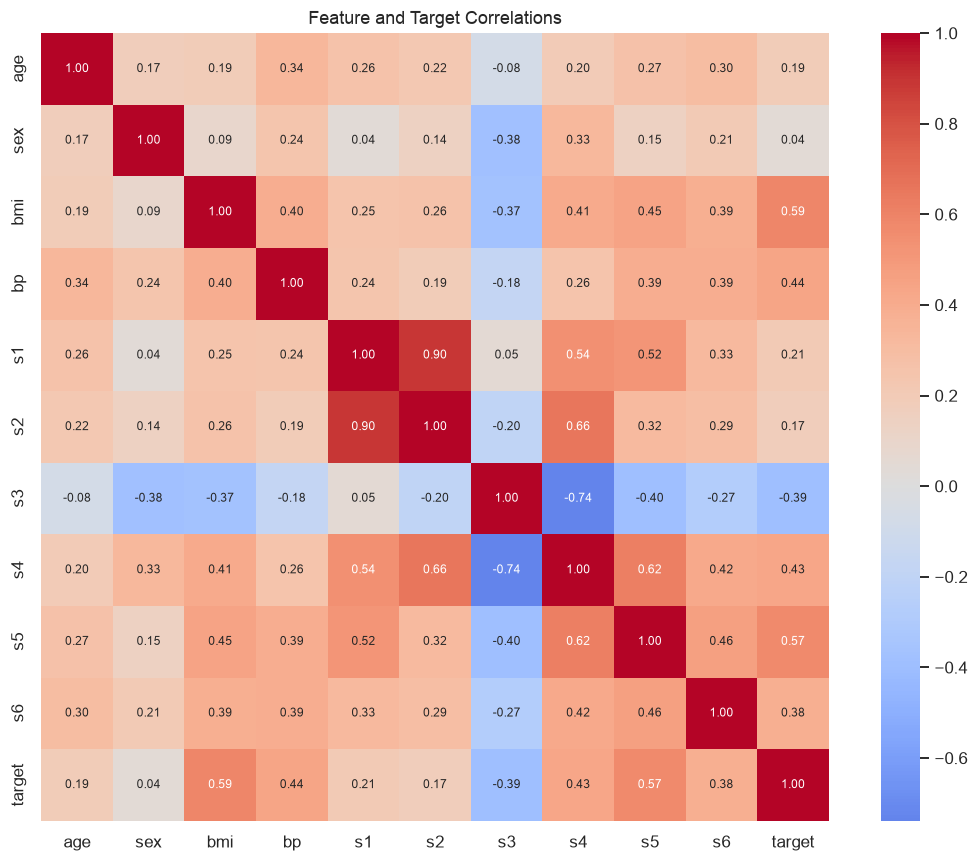

In [6]:
# Look for unexpected missing values or duplicate records without silently altering
# a benchmark dataset. Median imputation is fitted on training data in each pipeline.
if df.duplicated().any():
    print('Warning: duplicates detected; investigate these records before modeling.')
else:
    print('No duplicate records were found.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=df, x='target', bins=25, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Disease Progression (Target)')
axes[0].set_xlabel('Disease progression target')
sns.boxplot(y=df['target'], color='lightblue', ax=axes[1])
axes[1].set_title('Target Boxplot / Outlier Check')
axes[1].set_ylabel('Disease progression target')
plt.tight_layout()
plt.savefig(IMG_DIR / '01_target_distribution.png', bbox_inches='tight', dpi=160)
plt.show()

# Show each feature distribution and the correlation matrix.
feature_cols = list(diabetes.feature_names)
axarr = df[feature_cols].hist(figsize=(13, 9), bins=20, layout=(3, 4))
plt.suptitle('Distributions of the 10 Input Features', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(IMG_DIR / '02_feature_distributions.png', bbox_inches='tight', dpi=160)
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            annot_kws={'size': 8})
plt.title('Feature and Target Correlations')
plt.tight_layout()
plt.savefig(IMG_DIR / '03_correlation_heatmap.png', bbox_inches='tight', dpi=160)
plt.show()

### Preparation decisions

- **Missing values:** The loader normally contains no missing values; we still include a median imputer inside every modeling pipeline. This ensures any imputation is fit *only on training folds*.
- **Scaling:** Ridge and Lasso penalties depend on feature scale, so their polynomial inputs are standardized within the pipeline. We also standardize the unregularized polynomial model for a consistent numerical comparison.
- **Outliers:** We inspect the target distribution, but do not automatically remove valid observations. Deleting points without a defensible criterion could bias the analysis.
- **Leakage prevention:** Feature selection for simple regression is performed on the *training set only*, and all models share one test split.

### 2. Common train/test split and evaluation functions

Use **80% training / 20% testing** for every model. Report metrics for both sets so generalization gaps can be compared. The root mean squared error (RMSE) is reported in the same units as the target.

In [10]:
X = df[feature_cols].copy()
y = df['target'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Correlation is computed on training data only to avoid test-data leakage.
train_corr = X_train.corrwith(y_train)
best_feature = train_corr.abs().idxmax()
print(f'Training observations: {len(X_train)} | Testing observations: {len(X_test)}')
print('Single predictor selected by absolute training correlation:', best_feature)
print(f'Its training correlation with target: {train_corr[best_feature]:+.3f}')

results = []
fit_models = {}
test_predictions = {}

def evaluate_model(name, estimator, train_x, test_x):
    """Train, evaluate, and store one estimator using the shared split."""
    estimator.fit(train_x, y_train)
    train_pred = estimator.predict(train_x)
    test_pred = estimator.predict(test_x)
    train_rmse = float(np.sqrt(mean_squared_error(y_train, train_pred)))
    test_rmse = float(np.sqrt(mean_squared_error(y_test, test_pred)))
    row = {
        'Model': name,
        'Train MAE': mean_absolute_error(y_train, train_pred),
        'Train MSE': mean_squared_error(y_train, train_pred),
        'Train RMSE': train_rmse,
        'Train R²': r2_score(y_train, train_pred),
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Test MSE': mean_squared_error(y_test, test_pred),
        'Test RMSE': test_rmse,
        'Test R²': r2_score(y_test, test_pred),
        'RMSE Gap (Test-Train)': test_rmse - train_rmse,
    }
    results.append(row)
    fit_models[name] = estimator
    test_predictions[name] = test_pred
    display(pd.DataFrame([row]).round(3))
    return estimator

def actual_vs_predicted(y_actual, pred, title, filename):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sns.scatterplot(x=y_actual, y=pred, ax=ax, color='steelblue', alpha=0.75)
    low = float(min(np.min(y_actual), np.min(pred)))
    high = float(max(np.max(y_actual), np.max(pred)))
    ax.plot([low, high], [low, high], '--', color='black', label='Perfect prediction')
    ax.set(xlabel='Actual target', ylabel='Predicted target', title=title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(IMG_DIR / filename, bbox_inches='tight', dpi=160)
    plt.show()

Training observations: 353 | Testing observations: 89
Single predictor selected by absolute training correlation: bmi
Its training correlation with target: +0.605


### 3. Simple linear regression (one independent variable)

Select a single explanatory feature based on its **absolute correlation with the training target**. Fit an ordinary least squares line and plot the fitted prediction line against the held-out test observations.

,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Simple Linear,51.38,3854.113,62.082,0.366,52.26,4061.826,63.732,0.233,1.651


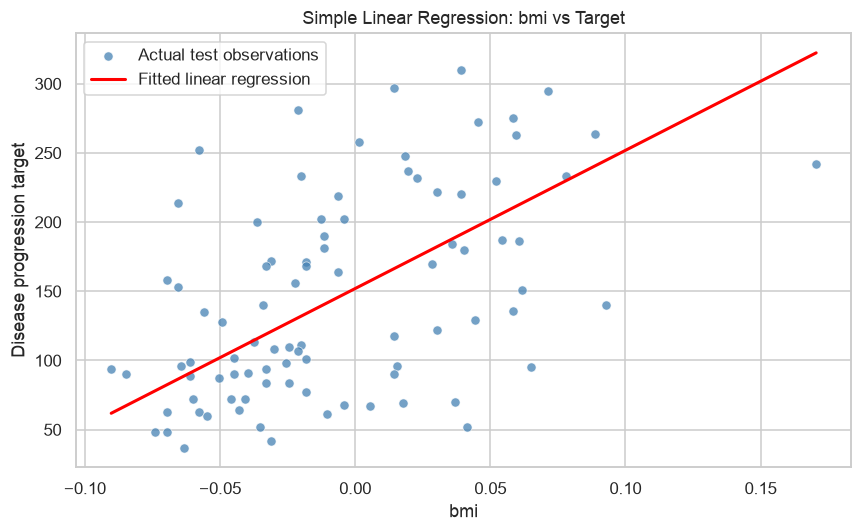

Slope: 998.578
Intercept: 152.003


In [11]:
simple_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regression', LinearRegression()),
])
simple_model = evaluate_model(
    'Simple Linear', simple_model,
    X_train[[best_feature]], X_test[[best_feature]]
)

x_line = np.linspace(X_test[best_feature].min(), X_test[best_feature].max(), 200)
x_line_df = pd.DataFrame({best_feature: x_line})
y_line = simple_model.predict(x_line_df)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_test[best_feature], y=y_test, label='Actual test observations', color='steelblue', alpha=0.75)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Fitted linear regression')
plt.xlabel(best_feature)
plt.ylabel('Disease progression target')
plt.title(f'Simple Linear Regression: {best_feature} vs Target')
plt.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / '04_simple_linear_fit.png', bbox_inches='tight', dpi=160)
plt.show()

print('Slope:', round(simple_model.named_steps['regression'].coef_[0], 3))
print('Intercept:', round(simple_model.named_steps['regression'].intercept_, 3))

### 4. Multiple linear regression (all 10 independent variables)

Fit a multivariable ordinary least squares model on all ten baseline features and visualize predictions versus actual target values. Unlike simple regression, this model can account for several predictors simultaneously.

,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Multiple Linear,43.484,2868.55,53.559,0.528,42.794,2900.194,53.853,0.453,0.295


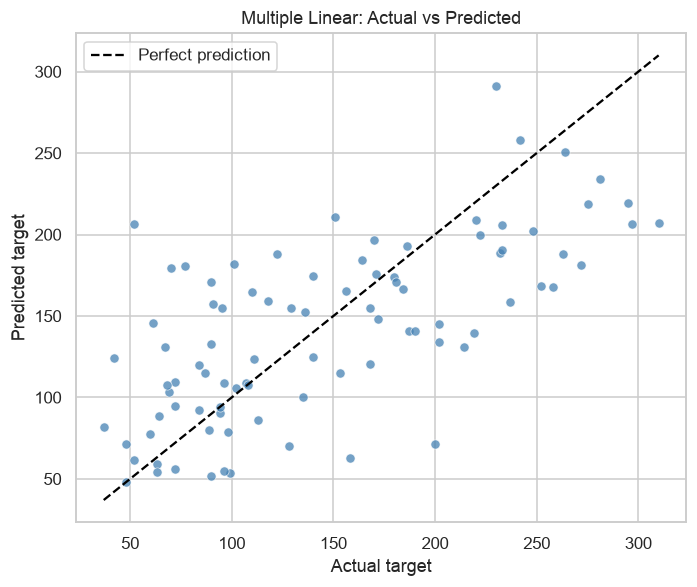

,Coefficient
s1,-931.49
s5,736.20
bmi,542.43
s2,518.06
bp,347.70
s4,275.32
sex,-241.96
s3,163.42
s6,48.67
age,37.90


In [12]:
multiple_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regression', LinearRegression()),
])
multiple_model = evaluate_model('Multiple Linear', multiple_model, X_train, X_test)
actual_vs_predicted(y_test, test_predictions['Multiple Linear'],
                    'Multiple Linear: Actual vs Predicted', '05_multiple_actual_vs_predicted.png')

multiple_coef = pd.Series(multiple_model.named_steps['regression'].coef_,
                          index=feature_cols, name='Coefficient')
display(multiple_coef.sort_values(key=abs, ascending=False).to_frame().round(2))

### 5. Polynomial regression and model complexity

Polynomial regression remains linear in its **coefficients**, but includes nonlinear feature combinations.

First, fit polynomial models using **all ten features** at degree 2 and degree 3. Then explore degrees 1, 2, 3, 5, 8, and 12 on the **one selected predictor** to illustrate the tradeoff between model flexibility, training error, and held-out error. Increasing training accuracy does **not** guarantee better generalization.

,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Polynomial (degree 2),39.143,2393.139,48.92,0.606,43.582,3096.028,55.642,0.416,6.722


,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Polynomial (degree 3),18.777,749.603,27.379,0.877,161.19,77808.802,278.942,-13.686,251.563


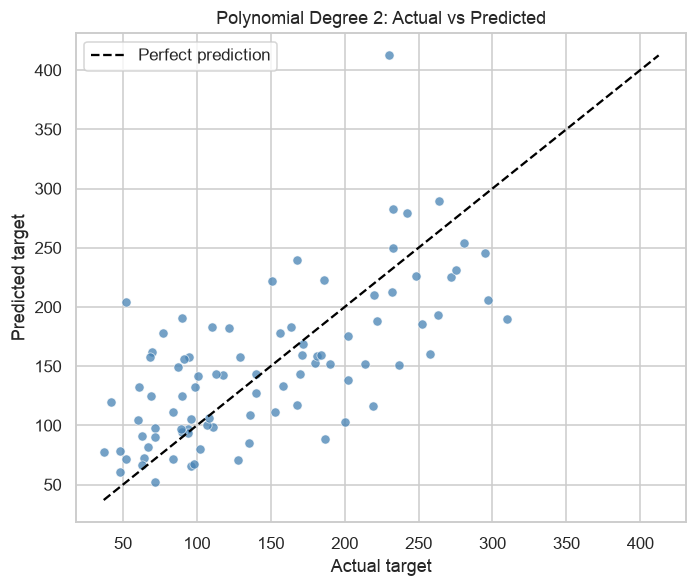

Degree 2 creates 65 features; degree 3 creates 285 features.
When the number of model terms approaches the number of training samples,
an unregularized polynomial model may fit noise and generalize poorly.


In [13]:
def polynomial_pipeline(degree, estimator=None):
    """Scale derived polynomial features and fit the specified regression estimator."""
    if estimator is None:
        estimator = LinearRegression()
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('regression', estimator),
    ])

poly2 = evaluate_model('Polynomial (degree 2)', polynomial_pipeline(2), X_train, X_test)
poly3 = evaluate_model('Polynomial (degree 3)', polynomial_pipeline(3), X_train, X_test)
actual_vs_predicted(y_test, test_predictions['Polynomial (degree 2)'],
                    'Polynomial Degree 2: Actual vs Predicted',
                    '06_polynomial_degree2_actual_vs_predicted.png')

n_poly2 = poly2.named_steps['poly'].n_output_features_
n_poly3 = poly3.named_steps['poly'].n_output_features_
print(f'Degree 2 creates {n_poly2} features; degree 3 creates {n_poly3} features.')
print('When the number of model terms approaches the number of training samples,')
print('an unregularized polynomial model may fit noise and generalize poorly.')

,Degree,Train RMSE,Test RMSE,Train R²,Test R²
0,1,62.082,63.732,0.366,0.233
1,2,62.043,63.914,0.367,0.229
2,3,62.036,63.753,0.367,0.233
3,5,61.837,63.921,0.371,0.229
4,8,61.116,88.743,0.385,-0.486
5,12,61.401,105.209,0.380,-1.089


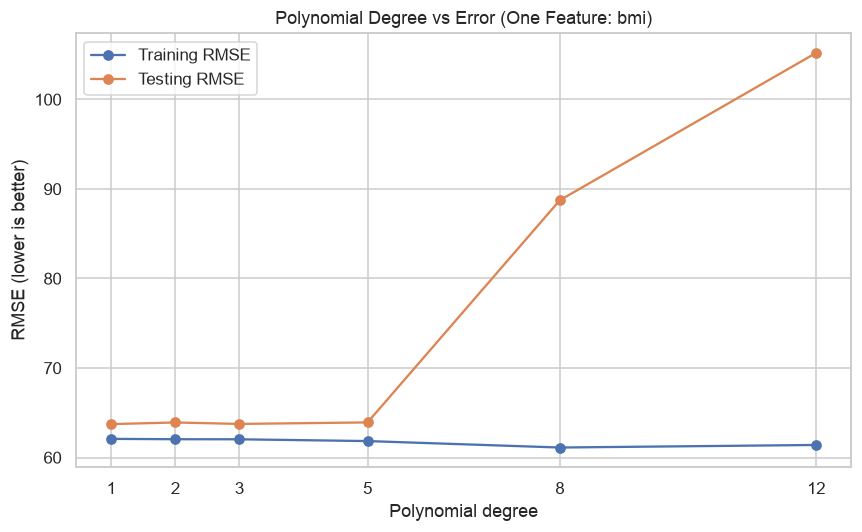

Lowest single-feature test RMSE occurs at degree 1.
Interpretation: Compare train and test errors; widening gaps suggest overfitting.


In [14]:
degree_rows = []
for degree in [1, 2, 3, 5, 8, 12]:
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('regression', LinearRegression()),
    ])
    model.fit(X_train[[best_feature]], y_train)
    pred_train = model.predict(X_train[[best_feature]])
    pred_test = model.predict(X_test[[best_feature]])
    degree_rows.append({
        'Degree': degree,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, pred_train)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'Train R²': r2_score(y_train, pred_train),
        'Test R²': r2_score(y_test, pred_test),
    })

degree_df = pd.DataFrame(degree_rows)
display(degree_df.round(3))
plt.figure(figsize=(8, 5))
plt.plot(degree_df['Degree'], degree_df['Train RMSE'], marker='o', label='Training RMSE')
plt.plot(degree_df['Degree'], degree_df['Test RMSE'], marker='o', label='Testing RMSE')
plt.title(f'Polynomial Degree vs Error (One Feature: {best_feature})')
plt.xlabel('Polynomial degree')
plt.ylabel('RMSE (lower is better)')
plt.xticks(degree_df['Degree'])
plt.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / '07_polynomial_complexity.png', bbox_inches='tight', dpi=160)
plt.show()

lowest_degree = degree_df.loc[degree_df['Test RMSE'].idxmin()]
print(f'Lowest single-feature test RMSE occurs at degree {int(lowest_degree["Degree"])}.')
print('Interpretation: Compare train and test errors; widening gaps suggest overfitting.')

### 6. Ridge (L2) and Lasso (L1) regression

Ridge adds an L2 penalty (squared coefficients); Lasso adds an L1 penalty (absolute coefficients) and can set some coefficients to exactly zero. We apply both to **degree-2 polynomial features** so their performance can be compared directly against unregularized degree-2 polynomial regression.

**Hyperparameter selection:** Use 5-fold cross-validation *on the training set only* to choose `alpha`, minimizing cross-validated RMSE. Standardization is included inside each cross-validation fold, preventing leakage. A larger `alpha` usually causes more shrinkage; excessively high regularization can underfit.

,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Ridge (degree 2),41.95,2668.831,51.661,0.561,41.573,2659.112,51.567,0.498,-0.094


,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Lasso (degree 2),44.967,2979.278,54.583,0.51,42.784,2711.001,52.067,0.488,-2.515


Best Ridge alpha: 100
Best Lasso alpha: 5
Best Ridge training CV RMSE: 57.569
Best Lasso training CV RMSE: 57.074


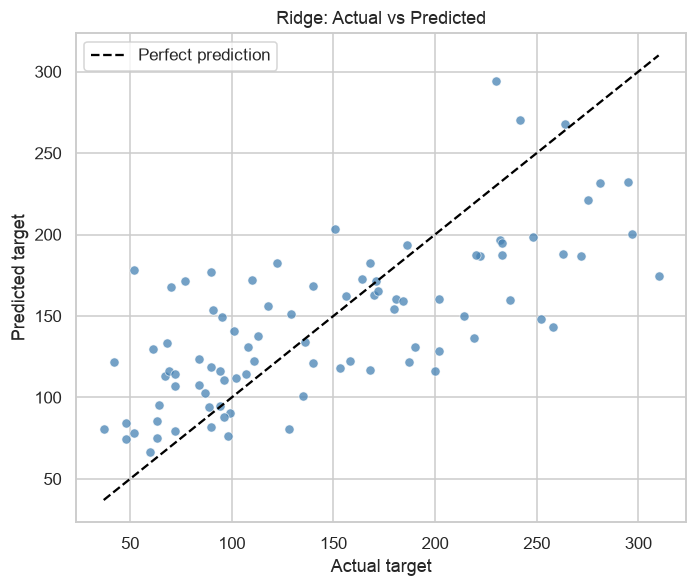

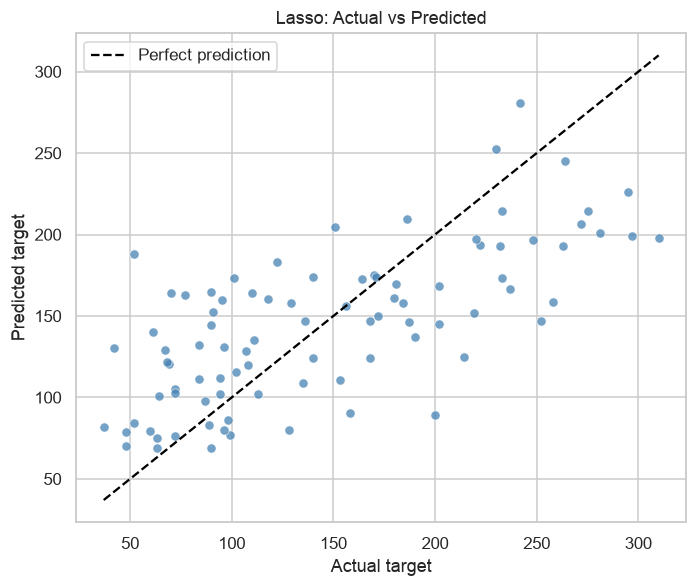

In [15]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]
lasso_alphas = [0.01, 0.1, 1, 5, 10, 20]

ridge_search = GridSearchCV(
    estimator=polynomial_pipeline(2, Ridge()),
    param_grid={'regression__alpha': ridge_alphas},
    cv=5,
    scoring='neg_root_mean_squared_error',
    refit=True,
    n_jobs=1,
)
lasso_search = GridSearchCV(
    estimator=polynomial_pipeline(2, Lasso(max_iter=50000, random_state=RANDOM_STATE)),
    param_grid={'regression__alpha': lasso_alphas},
    cv=5,
    scoring='neg_root_mean_squared_error',
    refit=True,
    n_jobs=1,
)

ridge_model = evaluate_model('Ridge (degree 2)', ridge_search, X_train, X_test)
lasso_model = evaluate_model('Lasso (degree 2)', lasso_search, X_train, X_test)
print('Best Ridge alpha:', ridge_search.best_params_['regression__alpha'])
print('Best Lasso alpha:', lasso_search.best_params_['regression__alpha'])
print('Best Ridge training CV RMSE:', round(-ridge_search.best_score_, 3))
print('Best Lasso training CV RMSE:', round(-lasso_search.best_score_, 3))

# GridSearchCV stores the selected model in best_estimator_.
actual_vs_predicted(y_test, test_predictions['Ridge (degree 2)'],
                    'Ridge: Actual vs Predicted', '08_ridge_actual_vs_predicted.png')
actual_vs_predicted(y_test, test_predictions['Lasso (degree 2)'],
                    'Lasso: Actual vs Predicted', '09_lasso_actual_vs_predicted.png')

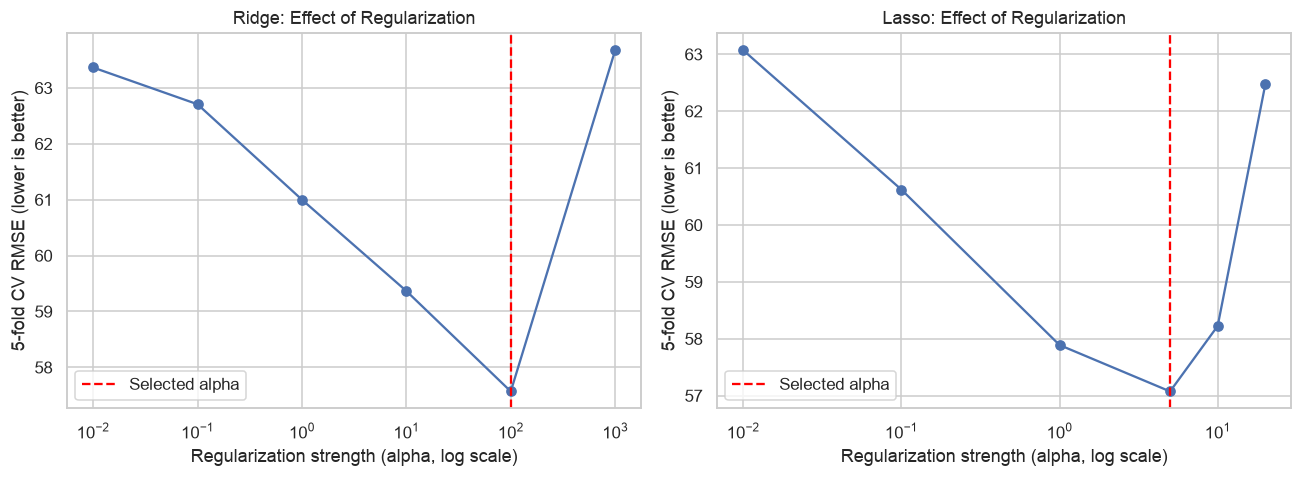

,Ridge coefficient,Lasso coefficient,absolute Ridge
bmi,17.842,24.414,17.842
s5,16.200,19.287,16.200
bp,14.075,11.894,14.075
s3,-9.507,-7.918,9.507
s4,6.425,0.000,6.425
bmi bp,5.018,1.723,5.018
bmi^2,4.851,2.580,4.851
age sex,4.843,2.114,4.843
sex^2,-4.602,-2.385,4.602
sex,-4.602,-0.002,4.602


Total polynomial features: 65
Nonzero Ridge coefficients: 65
Nonzero Lasso coefficients: 12


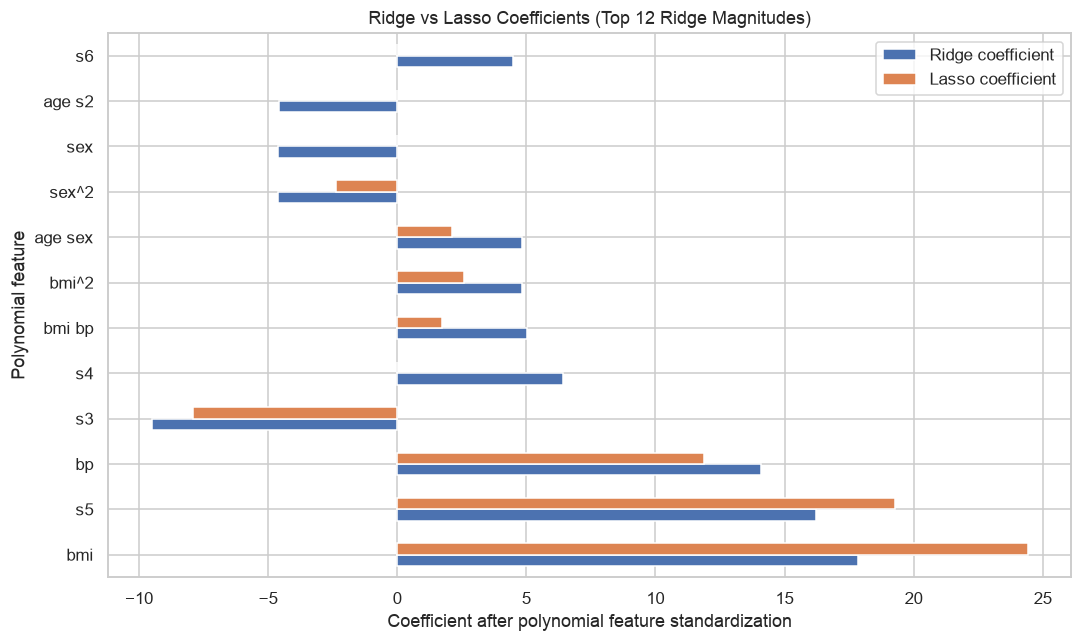

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, search, label in [
    (axes[0], ridge_search, 'Ridge'),
    (axes[1], lasso_search, 'Lasso'),
]:
    alphas = np.asarray(search.cv_results_['param_regression__alpha'], dtype=float)
    cv_rmse = -np.asarray(search.cv_results_['mean_test_score'], dtype=float)
    ax.plot(alphas, cv_rmse, marker='o')
    ax.axvline(search.best_params_['regression__alpha'], color='red', linestyle='--',
               label='Selected alpha')
    ax.set_xscale('log')
    ax.set_xlabel('Regularization strength (alpha, log scale)')
    ax.set_ylabel('5-fold CV RMSE (lower is better)')
    ax.set_title(f'{label}: Effect of Regularization')
    ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / '10_regularization_alpha_cv.png', bbox_inches='tight', dpi=160)
plt.show()

ridge_best = ridge_search.best_estimator_
lasso_best = lasso_search.best_estimator_
poly_feature_names = ridge_best.named_steps['poly'].get_feature_names_out(feature_cols)
ridge_coef = pd.Series(ridge_best.named_steps['regression'].coef_, index=poly_feature_names)
lasso_coef = pd.Series(lasso_best.named_steps['regression'].coef_, index=poly_feature_names)

comparison_coef = pd.DataFrame({'Ridge coefficient': ridge_coef,
                                'Lasso coefficient': lasso_coef})
comparison_coef['absolute Ridge'] = comparison_coef['Ridge coefficient'].abs()
display(comparison_coef.sort_values('absolute Ridge', ascending=False).head(15).round(3))
print('Total polynomial features:', len(poly_feature_names))
print('Nonzero Ridge coefficients:', int((ridge_coef.abs() > 1e-8).sum()))
print('Nonzero Lasso coefficients:', int((lasso_coef.abs() > 1e-8).sum()))

# Compare the most influential coefficients on a common standardized feature scale.
top_features = comparison_coef['absolute Ridge'].nlargest(12).index
comparison_coef.loc[top_features, ['Ridge coefficient', 'Lasso coefficient']].plot(
    kind='barh', figsize=(10, 6)
)
plt.title('Ridge vs Lasso Coefficients (Top 12 Ridge Magnitudes)')
plt.xlabel('Coefficient after polynomial feature standardization')
plt.ylabel('Polynomial feature')
plt.tight_layout()
plt.savefig(IMG_DIR / '11_ridge_vs_lasso_coefficients.png', bbox_inches='tight', dpi=160)
plt.show()

### 7. Model comparison, interpretation, and insights

All six entries use the **same 80/20 split**. Ranking models by test RMSE is descriptive final evaluation—not a signal to keep tuning based on the test set. Ridge and Lasso were tuned exclusively using cross-validation on the training partition.

**How to read the results:**

- **MAE:** average absolute prediction error. Lower is better.
- **MSE:** average squared prediction error; penalizes larger mistakes more heavily. Lower is better.
- **RMSE:** square root of MSE, in the target's units. Lower is better.
- **R²:** fraction of target variance explained relative to predicting its mean on the evaluated dataset. Higher is better (negative is possible).
- **Generalization gap:** `Test RMSE − Train RMSE`. A large positive gap suggests overfitting, though small gaps alone do not guarantee a good model.

,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,RMSE Gap (Test-Train)
0,Ridge (degree 2),41.950,2668.831,51.661,0.561,41.573,2659.112,51.567,0.498,-0.094
1,Lasso (degree 2),44.967,2979.278,54.583,0.510,42.784,2711.001,52.067,0.488,-2.515
2,Multiple Linear,43.484,2868.550,53.559,0.528,42.794,2900.194,53.853,0.453,0.295
3,Polynomial (degree 2),39.143,2393.139,48.920,0.606,43.582,3096.028,55.642,0.416,6.722
4,Simple Linear,51.380,3854.113,62.082,0.366,52.260,4061.826,63.732,0.233,1.651
5,Polynomial (degree 3),18.777,749.603,27.379,0.877,161.190,77808.802,278.942,-13.686,251.563


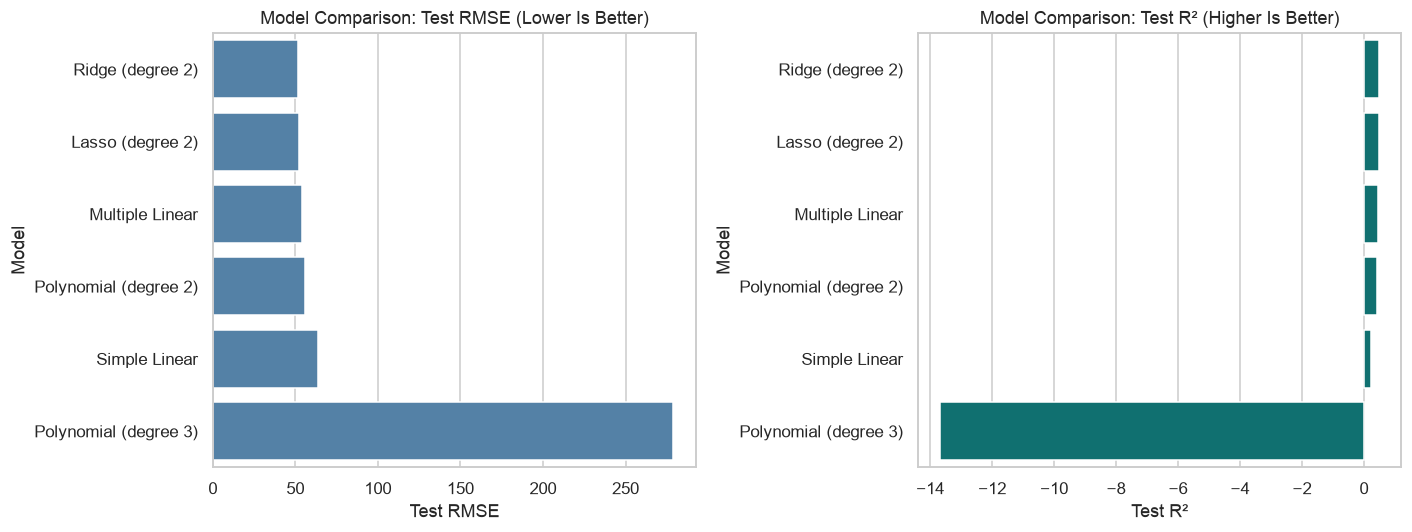

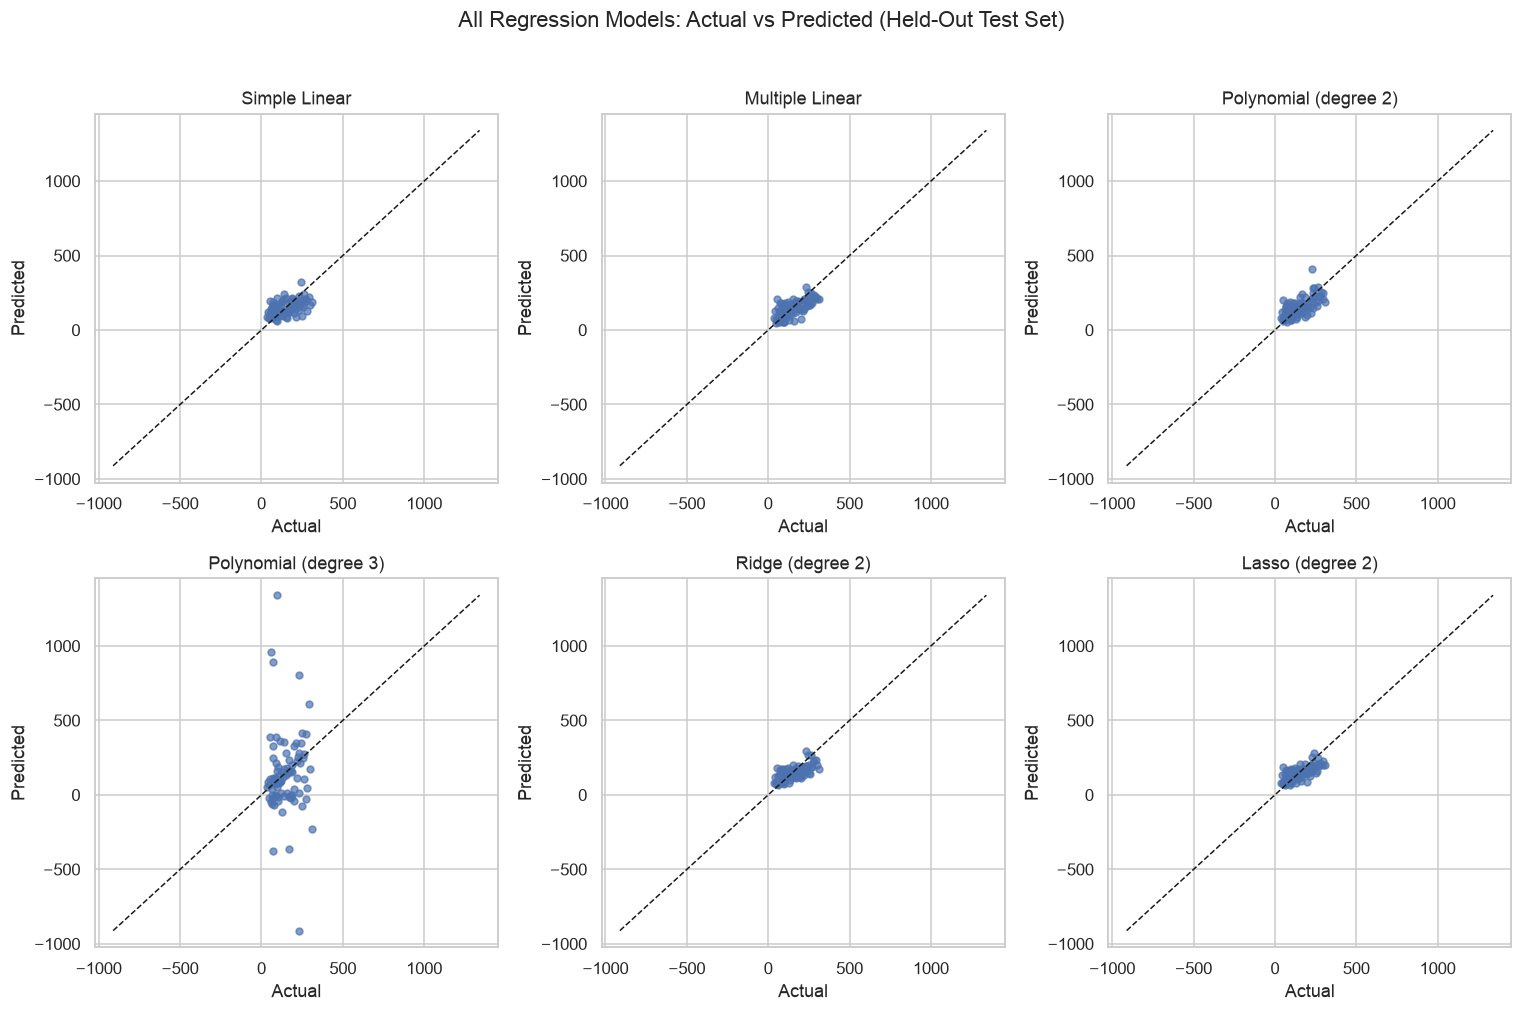

In [17]:
comparison = pd.DataFrame(results).sort_values('Test RMSE').reset_index(drop=True)
display(comparison.round(3))
comparison.to_csv('model_comparison.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=comparison, x='Test RMSE', y='Model', ax=axes[0], color='steelblue')
axes[0].set_title('Model Comparison: Test RMSE (Lower Is Better)')
sns.barplot(data=comparison, x='Test R²', y='Model', ax=axes[1], color='teal')
axes[1].set_title('Model Comparison: Test R² (Higher Is Better)')
plt.tight_layout()
plt.savefig(IMG_DIR / '12_model_comparison.png', bbox_inches='tight', dpi=160)
plt.show()

# Actual vs predicted for every candidate on identical test observations.
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
low = float(min(y_test.min(), *(np.min(v) for v in test_predictions.values())))
high = float(max(y_test.max(), *(np.max(v) for v in test_predictions.values())))
for ax, (label, pred) in zip(axes.flat, test_predictions.items()):
    ax.scatter(y_test, pred, alpha=0.7, s=20)
    ax.plot([low, high], [low, high], 'k--', linewidth=1)
    ax.set(xlabel='Actual', ylabel='Predicted', title=label)
plt.suptitle('All Regression Models: Actual vs Predicted (Held-Out Test Set)', y=1.02)
plt.tight_layout()
plt.savefig(IMG_DIR / '13_all_models_actual_vs_predicted.png', bbox_inches='tight', dpi=160)
plt.show()

In [20]:
best = comparison.iloc[0]
worst_gap = comparison.loc[comparison['RMSE Gap (Test-Train)'].idxmax()]
poly2_row = comparison.loc[comparison['Model'] == 'Polynomial (degree 2)'].iloc[0]
ridge_row = comparison.loc[comparison['Model'] == 'Ridge (degree 2)'].iloc[0]
lasso_row = comparison.loc[comparison['Model'] == 'Lasso (degree 2)'].iloc[0]

print('LAB SUMMARY')
print('-' * 68)
print(f'1. Best test RMSE: {best["Model"]} = {best["Test RMSE"]:.2f}; '
      f'test R² = {best["Test R²"]:.3f}.')
print(f'2. Largest test-train RMSE gap: {worst_gap["Model"]} '
      f'({worst_gap["RMSE Gap (Test-Train)"]:+.2f}); inspect for overfitting.')
print(f'3. Unregularized degree-2 polynomial test RMSE: {poly2_row["Test RMSE"]:.2f}.')
print(f'4. Ridge degree-2 polynomial test RMSE: {ridge_row["Test RMSE"]:.2f}.')
print(f'5. Lasso degree-2 polynomial test RMSE: {lasso_row["Test RMSE"]:.2f}.')
print(f'6. Lasso retained {int((lasso_coef.abs() > 1e-8).sum())} of '
      f'{len(poly_feature_names)} coefficients; Ridge retained '
      f'{int((ridge_coef.abs() > 1e-8).sum())}.')

if ridge_row['Test RMSE'] < poly2_row['Test RMSE']:
    print('7. Ridge improved held-out RMSE over unregularized degree-2 polynomial regression.')
else:
    print('7. Ridge did not improve held-out RMSE over unregularized degree-2 polynomial regression.')
if lasso_row['Test RMSE'] < poly2_row['Test RMSE']:
    print('8. Lasso improved held-out RMSE over unregularized degree-2 polynomial regression.')
else:
    print('8. Lasso did not improve held-out RMSE over unregularized degree-2 polynomial regression.')
print('\nCaution: These are associations from a small benchmark dataset, not causal findings.')

LAB SUMMARY
--------------------------------------------------------------------
1. Best test RMSE: Ridge (degree 2) = 51.57; test R² = 0.498.
2. Largest test-train RMSE gap: Polynomial (degree 3) (+251.56); inspect for overfitting.
3. Unregularized degree-2 polynomial test RMSE: 55.64.
4. Ridge degree-2 polynomial test RMSE: 51.57.
5. Lasso degree-2 polynomial test RMSE: 52.07.
6. Lasso retained 12 of 65 coefficients; Ridge retained 65.
7. Ridge improved held-out RMSE over unregularized degree-2 polynomial regression.
8. Lasso improved held-out RMSE over unregularized degree-2 polynomial regression.

Caution: These are associations from a small benchmark dataset, not causal findings.


### Discussion and conclusions

**Data preparation:** The dataset has 442 observations and ten continuous input features. The exploratory visualizations inspect the target distribution, feature distributions, and relationships. Because the benchmark data normally contain no missing values, imputation serves as a leakage-safe safeguard rather than changing any observations.

**Simple vs. multiple linear regression:** A single-feature model is easier to interpret, but it cannot capture the full information contained in all ten predictors. Compare their **test RMSE and R²** above to evaluate whether the added explanatory variables improve predictive accuracy.

**Polynomial regression:** Degree-2 and degree-3 polynomial features capture nonlinear interactions and substantially increase model complexity. Compare train and test RMSE, along with the degree-complexity chart, to describe whether a lower training error coincides with worse generalization. A positive widening gap is evidence consistent with overfitting.

**Ridge vs. Lasso:** Ridge stabilizes flexible models by shrinking the magnitude of coefficients, whereas Lasso can remove some terms completely. The cross-validation charts show how training-fold validation RMSE varies with `alpha`. Large penalties can lead to **underfitting**, while weak penalties can allow **overfitting**. The coefficient plot illustrates L1 sparsity versus L2 shrinkage.

**Overall result:** Use the generated model comparison table and automated summary above to cite your **actual measured values** for MAE, MSE, RMSE, and R². Prefer the model that balances held-out predictive accuracy, a reasonable train/test gap, and interpretability. Avoid claiming that the most complex model must be best.

**Limitations:** There are only 442 observations. Scores can change with the random split, correlation does not establish causation, and no independent external dataset is available. A future enhancement could use repeated cross-validation or an external validation cohort.

